# Wine Quality (Red) — Regression on a 0-10 score

UCI red wine quality, 1599 rows, 11 physicochemical features, target is a 0-10 quality rating from sommeliers. I'm treating it as regression first, then doing a sanity check on the ordinal-classification framing because the target is integer-valued and the classes are super imbalanced (almost everything is a 5 or 6).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import urllib.request

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, classification_report

np.random.seed(0)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
DATA_DIR = Path("../../data/wine_quality"); DATA_DIR.mkdir(parents=True, exist_ok=True)

fpath = DATA_DIR / "winequality-red.csv"
if not fpath.exists():
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    urllib.request.urlretrieve(url, fpath)

df = pd.read_csv(fpath, sep=";")
print(df.shape, df.columns.tolist())
df.head()


(1599, 12) ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## what does quality look like?

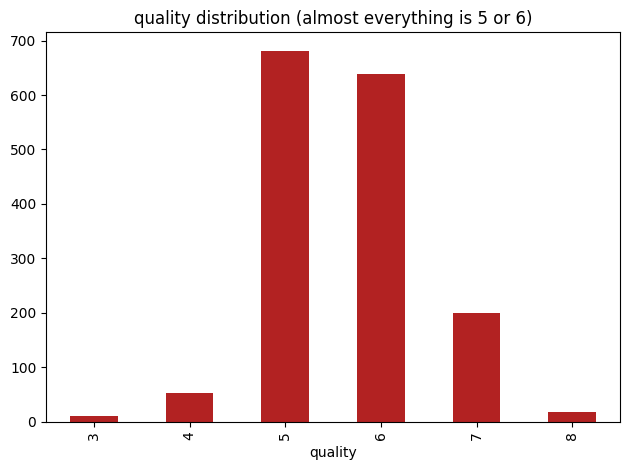

count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64


In [2]:
df["quality"].value_counts().sort_index().plot(kind="bar", color="firebrick")
plt.title("quality distribution (almost everything is 5 or 6)")
plt.tight_layout(); plt.savefig(ART / "quality_hist.png", dpi=120); plt.show()
print(df["quality"].describe())


## regression: ridge vs random forest

In [3]:
features = [c for c in df.columns if c != "quality"]
X = df[features].values
y = df["quality"].values.astype(float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

for name, m in [("Ridge", Ridge(alpha=1.0)),
                ("RF",    RandomForestRegressor(n_estimators=300, random_state=0))]:
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{name:6s} RMSE={rmse:.3f}  MAE={mae:.3f}  R2={r2:.3f}")


Ridge  RMSE=0.619  MAE=0.469  R2=0.332


RF     RMSE=0.567  MAE=0.408  R2=0.438


## what if I just round to the nearest integer?

In [4]:
# treat the regression output as an ordinal prediction by rounding to int
rf = RandomForestRegressor(n_estimators=300, random_state=0)
rf.fit(X_train, y_train)
pred_int = np.clip(np.round(rf.predict(X_test)), 3, 8).astype(int)
print(f"exact-match accuracy after rounding: {accuracy_score(y_test.astype(int), pred_int):.3f}")
print(f"within-1 accuracy: {np.mean(np.abs(y_test - pred_int) <= 1):.3f}")


exact-match accuracy after rounding: 0.700
within-1 accuracy: 0.972


## feature importance

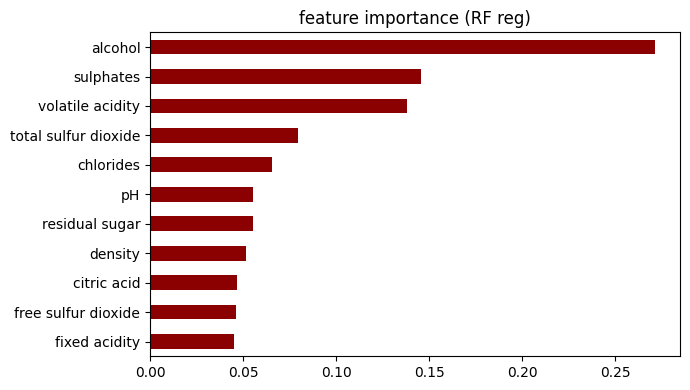

In [5]:
fi = pd.Series(rf.feature_importances_, index=features).sort_values()
fi.plot(kind="barh", figsize=(7, 4), color="darkred"); plt.title("feature importance (RF reg)")
plt.tight_layout(); plt.savefig(ART / "fi.png", dpi=120); plt.show()


## thoughts

Alcohol and volatile acidity are clearly the strongest predictors. R^2 around 0.4-0.5 is the realistic ceiling here — the labels are noisy because they're sommelier scores, and you can't reliably distinguish a 5 from a 6 with chemistry alone. The "within-1" accuracy is more useful as a metric than exact match.

I didn't try a real ordinal model (proportional-odds logistic). For 6 effective classes with this much imbalance, the regress-and-round trick is already kind of doing the right thing.
